# Moedas

O pacote tem 2 APIs que dão acesso a informações de moedas.

- [API OData de Moedas](#api-odata-de-moedas) com cotações de taxas de câmbio
- Webscraping no [Conversor de Moedas](#conversor-de-moedas)

## API OData de Moedas

A classe `bcb.PTAX` retorna cotações de moedas obtidas a partir da [API de Moedas](https://olinda.bcb.gov.br/olinda/servico/PTAX/versao/v1/documentacao) do BCB. Esta implementação é mais estável que a do [Conversor de Moedas](#conversor-de-moedas). O método `describe` mostra os *endpoints*, parâmetros e propriedades disponíveis.

In [1]:
from bcb import PTAX
ptax = PTAX()
ptax.describe()

EntitySets:

EntitySet (Endpoint): Moedas
EntityType: br.gov.bcb.olinda.servico.PTAX.TipoMoeda
Properties: simbolo<str>, nomeFormatado<str>, tipoMoeda<str>
FunctionImports:

Function: CotacaoMoedaPeriodoFechamento
Parameters: codigoMoeda <str>, dataInicialCotacao <str>, dataFinalCotacao <str>
EntitySet: _CotacaoMoedaPeriodoFechamento
EntityType: br.gov.bcb.olinda.servico.PTAX.TipoCotacaoDolarAberturaOuIntermediario
Properties: cotacaoCompra <float>, cotacaoVenda <float>, dataHoraCotacao <str>, tipoBoletim <str>

Function: CotacaoMoedaAberturaOuIntermediario
Parameters: codigoMoeda <str>, dataCotacao <str>
EntitySet: _CotacaoMoedaAberturaOuIntermediario
EntityType: br.gov.bcb.olinda.servico.PTAX.TipoCotacaoDolarAberturaOuIntermediario
Properties: cotacaoCompra <float>, cotacaoVenda <float>, dataHoraCotacao <str>, tipoBoletim <str>

Function: CotacaoMoedaDia
Parameters: moeda <str>, dataCotacao <str>
EntitySet: _CotacaoMoedaDia
EntityType: br.gov.bcb.olinda.servico.PTAX.TipoCotacaoMoeda


In [2]:
ptax.describe('Moedas')

ep = ptax.get_endpoint('Moedas')
ep.query().limit(10).collect()


EntitySet (Endpoint): Moedas
EntityType: br.gov.bcb.olinda.servico.PTAX.TipoMoeda
Properties: simbolo<str>, nomeFormatado<str>, tipoMoeda<str>


,simbolo,nomeFormatado,tipoMoeda
0,AUD,Dólar australiano,B
1,CAD,Dólar canadense,A
2,CHF,Franco suíço,A
3,DKK,Coroa dinamarquesa,A
4,EUR,Euro,B
5,GBP,Libra Esterlina,B
6,JPY,Iene,A
7,NOK,Coroa norueguesa,A
8,SEK,Coroa sueca,A
9,USD,Dólar dos Estados Unidos,A


In [3]:
ptax.describe('CotacaoMoedaDia')

ep = ptax.get_endpoint('CotacaoMoedaDia')
(ep.query()
   .parameters(moeda='AUD', dataCotacao='2022-01-31')
   .collect())


Function: CotacaoMoedaDia
Parameters: moeda <str>, dataCotacao <str>
EntitySet: _CotacaoMoedaDia
EntityType: br.gov.bcb.olinda.servico.PTAX.TipoCotacaoMoeda
Properties: paridadeCompra <float>, paridadeVenda <float>, cotacaoCompra <float>, cotacaoVenda <float>, dataHoraCotacao <str>, tipoBoletim <str>


,paridadeCompra,paridadeVenda,cotacaoCompra,cotacaoVenda,dataHoraCotacao,tipoBoletim
0,0.7051,0.7053,3.8001,3.8016,2022-01-31 10:11:20.549,Abertura
1,0.7068,0.7070,3.7911,3.7926,2022-01-31 11:04:17.576,Intermediário
2,0.7066,0.7068,3.7920,3.7935,2022-01-31 12:02:19.723,Intermediário
3,0.7051,0.7052,3.7422,3.7432,2022-01-31 13:07:02.500,Intermediário
4,0.7051,0.7052,3.7771,3.7780,2022-01-31 13:07:02.511,Fechamento PTAX


Os parâmetros de data da PTAX aceitam strings ISO (`YYYY-MM-DD`), `datetime.date`, `datetime.datetime` e `pandas.Timestamp`. Strings já no formato PTAX também continuam aceitas. A biblioteca converte os valores generalizados para o formato aceito pelo serviço PTAX: `MM-DD-YYYY` (mês/dia/ano, sem zero à esquerda).

In [4]:
ptax.describe('CotacaoMoedaPeriodo')

ep = ptax.get_endpoint('CotacaoMoedaPeriodo')
(ep.query()
   .parameters(moeda='AUD',
               dataInicial='2022-01-01',
               dataFinalCotacao='2022-01-05')
   .collect())


Function: CotacaoMoedaPeriodo
Parameters: moeda <str>, dataInicial <str>, dataFinalCotacao <str>
EntitySet: _CotacaoMoedaPeriodo
EntityType: br.gov.bcb.olinda.servico.PTAX.TipoCotacaoMoeda
Properties: paridadeCompra <float>, paridadeVenda <float>, cotacaoCompra <float>, cotacaoVenda <float>, dataHoraCotacao <str>, tipoBoletim <str>


,paridadeCompra,paridadeVenda,cotacaoCompra,cotacaoVenda,dataHoraCotacao,tipoBoletim
0,0.7243,0.7244,4.0477,4.0487,2022-01-03 10:04:22.186,Abertura
1,0.7221,0.7223,4.0612,4.0628,2022-01-03 11:11:42.883,Intermediário
2,0.7197,0.7198,4.0623,4.0633,2022-01-03 12:09:19.760,Intermediário
3,0.7186,0.7188,4.0704,4.0719,2022-01-03 13:11:50.353,Intermediário
4,0.7186,0.7188,4.0459,4.0475,2022-01-03 13:11:50.357,Fechamento
5,0.7188,0.7189,4.0901,4.0911,2022-01-04 10:05:22.015,Abertura
6,0.7208,0.7209,4.1096,4.1106,2022-01-04 11:05:20.148,Intermediário
7,0.7217,0.7219,4.0767,4.0782,2022-01-04 12:10:19.466,Intermediário
8,0.7246,0.7248,4.1066,4.1082,2022-01-04 13:08:59.118,Intermediário
9,0.7246,0.7248,4.1136,4.1151,2022-01-04 13:08:59.123,Fechamento


## Conversor de Moedas

O módulo `bcb.currency` obtém dados de moedas do conversor de moedas do Banco Central através de webscraping. Os parâmetros `start` e `end` aceitam strings `YYYY-MM-DD`, `datetime.date`, `datetime.datetime` ou `bcb.utils.Date`.

Para consultas longas ou respostas lentas, informe `timeout` na chamada. O valor é usado em cada requisição HTTP feita por `currency.get` na chamada corrente, incluindo a busca inicial das listas de moedas quando elas ainda não estiverem em cache.

``` python
from bcb import currency

df = currency.get("USD", start="1980-01-01", end="2026-01-01", timeout=120)
moedas = currency.get_currency_list(timeout=120)
```

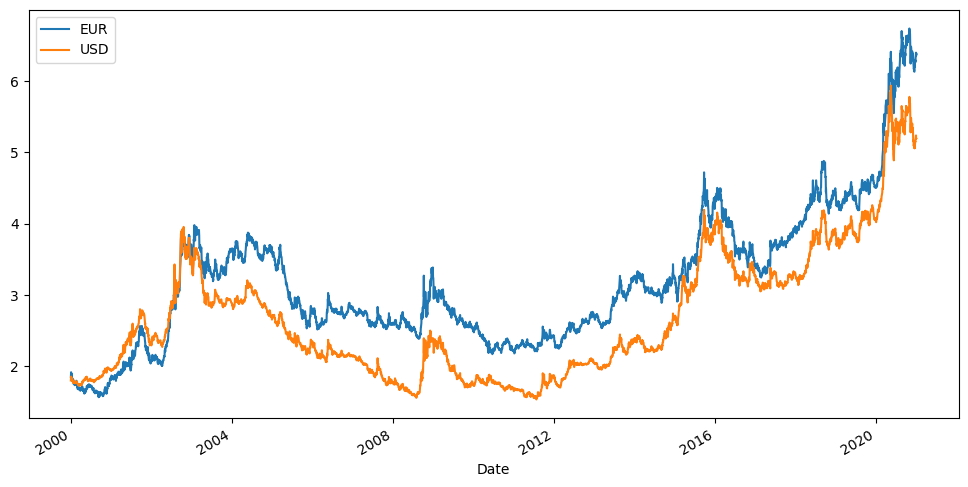

In [5]:
from bcb import currency
df = currency.get(['USD', 'EUR'],
                  start='2000-01-01',
                  end='2021-01-01',
                  side='ask')
df.head()

df.plot(figsize=(12, 6));

In [6]:
currency.get_currency_list().head()

,code,name,symbol,country_code,country_name,type,exclusion_date
0,5,AFEGANE AFEGANIST,AFN,132,AFEGANISTAO ...,A,NaT
1,785,RANDE/AFRICA SUL,ZAR,7560,AFRICA DO SUL ...,A,NaT
2,490,LEK ALBANIA REP,ALL,175,"ALBANIA, REPUBLICA DA ...",A,NaT
3,610,MARCO ALEMAO,DEM,230,ALEMANHA ...,A,2002-01-02
4,978,EURO,EUR,230,ALEMANHA ...,B,NaT


### Formato tidy em moedas

Por padrão, `bcb.currency.get` retorna um DataFrame no formato largo. Para retornar uma tabela longa, use `tidy=True`. Nesse modo, o DataFrame tem as colunas `Date`, `symbol`, `side` e `value`.

In [7]:
currency.get(['USD', 'EUR'],
             start='2024-01-01',
             end='2024-01-31',
             side='both',
             tidy=True).head()

,Date,symbol,side,value
0,2024-01-02,USD,bid,4.8910
1,2024-01-03,USD,bid,4.9206
2,2024-01-04,USD,bid,4.9182
3,2024-01-05,USD,bid,4.8893
4,2024-01-08,USD,bid,4.8844


O parâmetro `tidy` só afeta o retorno `output='dataframe'`. Quando `output='text'` é usado, a função continua retornando o CSV bruto.

### Obtendo o CSV bruto

Para pipelines de dados onde o dado bruto deve ser persistido antes de qualquer transformação, o parâmetro `output='text'` pode ser passado à função `bcb.currency.get`.

Para um único símbolo é retornada uma `str` com o CSV bruto; para múltiplos símbolos é retornado um `dict` mapeando símbolo ISO → CSV string.

``` python
from bcb import currency

# único símbolo → str (CSV)
raw = currency.get('USD', start='2024-01-01', end='2024-01-31', output='text')

# múltiplos símbolos → dict[str, str]
raws = currency.get(['USD', 'EUR'], start='2024-01-01', end='2024-01-31', output='text')
# raws['USD'] → CSV string
# raws['EUR'] → CSV string

# salvar em disco
with open('usd_raw.csv', 'w') as f:
    f.write(raw)
```

O CSV retornado usa ponto-e-vírgula como separador, datas no formato `DDMMYYYY` e vírgula como separador decimal — exatamente como devolvido pelo serviço de câmbio do BCB. O comportamento padrão (retorno de DataFrame) é mantido quando o parâmetro não é informado.